# CSE516 M3 — Results and Analysis

This notebook evaluates the proposed limitation solution against its baseline.

- **Baseline PGM:** team outcomes only.
- **Proposed PGM extension:** team outcomes plus individual performance observations.
- **Primary KPI:** individual skill MAE/RMSE against known synthetic ground truth.
- **Probability KPIs:** held-out team-outcome log-loss and Brier score.
- **Other KPIs:** runtime, approximate posterior uncertainty, optimizer iterations/success.
- **Robustness:** multiple seeds, sample size, missing observations, observation noise.
- **Statistics:** paired comparisons, mean ± standard deviation, 95% bootstrap confidence intervals.

The models are compared under matched synthetic datasets and seeds. This is synthetic validation, not real ATP validation. The model is a simplified temporal PGM using MAP/Laplace inference, not the complete published TTT EP package.

## 1. Install and import

In [22]:
%pip -q install numpy pandas scipy matplotlib

## 2. Model implementation

In [23]:
import numpy as np, pandas as pd, time, json, os
from scipy.optimize import minimize
from scipy.special import expit
from scipy.sparse import lil_matrix, csc_matrix
from scipy.sparse.linalg import spsolve

N_PLAYERS = 12
N_TIMES = 30
MATCHES_PER_TIME = 12
INITIAL_SD = 1.0
DRIFT_SD = 0.12
TEAM_TEMP = 0.8
OBS_SD_DEFAULT = 0.65

def simulate_doubles(seed=42, matches_per_time=MATCHES_PER_TIME,
                     obs_noise=OBS_SD_DEFAULT, missing_rate=0.0):
    """Generate synthetic doubles matches, latent skills, team outcomes and individual observations."""
    rng = np.random.default_rng(seed)
    truth = np.zeros((N_TIMES, N_PLAYERS))
    truth[0] = rng.normal(0, INITIAL_SD, N_PLAYERS)
    for t in range(1, N_TIMES):
        truth[t] = truth[t-1] + rng.normal(0, DRIFT_SD, N_PLAYERS)
    rows=[]
    for t in range(N_TIMES):
        for _ in range(matches_per_time):
            ps = rng.choice(N_PLAYERS, 4, replace=False)
            a,b = ps[:2], ps[2:]
            pwin = expit((truth[t,a].mean()-truth[t,b].mean())/TEAM_TEMP)
            win = int(rng.random() < pwin)
            obs = {}
            for p in ps:
                obs[int(p)] = truth[t,p] + rng.normal(0, obs_noise)
                if rng.random() < missing_rate:
                    obs[int(p)] = np.nan
            rows.append(dict(time=t,a1=int(a[0]),a2=int(a[1]),b1=int(b[0]),b2=int(b[1]),
                             a_wins=win,perf_a1=obs[int(a[0])],perf_a2=obs[int(a[1])],
                             perf_b1=obs[int(b[0])],perf_b2=obs[int(b[1])]))
    return truth, pd.DataFrame(rows)

def fit_skill_model(train, use_individual_obs=True, obs_sd=OBS_SD_DEFAULT,
                    drift_sd=DRIFT_SD, team_temp=TEAM_TEMP):
    """MAP inference in a temporal Bayesian network with Gaussian random-walk priors."""
    d=N_TIMES*N_PLAYERS
    def ix(t,p): return int(t)*N_PLAYERS+int(p)
    Q=lil_matrix((d,d),dtype=float)
    for p in range(N_PLAYERS):
        Q[ix(0,p),ix(0,p)] += 1/INITIAL_SD**2
        for t in range(1,N_TIMES):
            i,j=ix(t,p),ix(t-1,p)
            q=1/drift_sd**2
            Q[i,i]+=q; Q[j,j]+=q; Q[i,j]-=q; Q[j,i]-=q
    Q=csc_matrix(Q)
    records=list(train.itertuples(index=False))
    def fun(x):
        val=0.5*float(x@(Q@x)); grad=Q@x
        for r in records:
            t=int(r.time); ids=[ix(t,r.a1),ix(t,r.a2),ix(t,r.b1),ix(t,r.b2)]
            z=(x[ids[0]]+x[ids[1]]-x[ids[2]]-x[ids[3]])/(2*team_temp)
            y=float(r.a_wins)
            val += np.logaddexp(0,z)-y*z
            g=(expit(z)-y)/(2*team_temp)
            grad[ids[0]]+=g; grad[ids[1]]+=g; grad[ids[2]]-=g; grad[ids[3]]-=g
        if use_individual_obs:
            iv=1/obs_sd**2
            for r in records:
                t=int(r.time)
                for p,o in [(r.a1,r.perf_a1),(r.a2,r.perf_a2),(r.b1,r.perf_b1),(r.b2,r.perf_b2)]:
                    if pd.notna(o):
                        i=ix(t,p); res=x[i]-float(o)
                        val += .5*res*res*iv; grad[i]+=res*iv
        return val,np.asarray(grad)
    opt=minimize(fun,np.zeros(d),jac=True,method="L-BFGS-B",
                 options={"maxiter":500,"ftol":1e-9})
    H=Q.tolil(copy=True); x=opt.x
    for r in records:
        t=int(r.time); ids=[ix(t,r.a1),ix(t,r.a2),ix(t,r.b1),ix(t,r.b2)]
        z=(x[ids[0]]+x[ids[1]]-x[ids[2]]-x[ids[3]])/(2*team_temp)
        pr=expit(z); w=pr*(1-pr)/(4*team_temp**2)
        sg=[1,1,-1,-1]
        for a in range(4):
            for b in range(4): H[ids[a],ids[b]] += w*sg[a]*sg[b]
    if use_individual_obs:
        iv=1/obs_sd**2
        for r in records:
            t=int(r.time)
            for p,o in [(r.a1,r.perf_a1),(r.a2,r.perf_a2),(r.b1,r.perf_b1),(r.b2,r.perf_b2)]:
                if pd.notna(o): H[ix(t,p),ix(t,p)] += iv
    H=csc_matrix(H)
    # diagonal of inverse Hessian for Laplace marginal posterior variances
    diag=np.empty(d)
    for j in range(d):
        e=np.zeros(d); e[j]=1
        diag[j]=spsolve(H,e)[j]
    return opt.x.reshape(N_TIMES,N_PLAYERS),np.sqrt(np.maximum(diag,0)).reshape(N_TIMES,N_PLAYERS),opt

def skill_metrics(mu, truth, start):
    e=mu[start:]-truth[start:]
    return float(np.mean(np.abs(e))),float(np.sqrt(np.mean(e**2)))

def predict_metrics(mu, test):
    pp=[]; yy=[]
    for r in test.itertuples(index=False):
        t=int(r.time)
        margin=(mu[t,r.a1]+mu[t,r.a2]-mu[t,r.b1]-mu[t,r.b2])/2
        pp.append(np.clip(expit(margin/TEAM_TEMP),1e-9,1-1e-9)); yy.append(int(r.a_wins))
    p=np.array(pp); y=np.array(yy)
    ll=float(-np.mean(y*np.log(p)+(1-y)*np.log(1-p)))
    br=float(np.mean((p-y)**2))
    return ll,br,p,y

def run_experiment(seed=42, matches_per_time=MATCHES_PER_TIME,
                   obs_noise=OBS_SD_DEFAULT, missing_rate=0.0, obs_sd_model=OBS_SD_DEFAULT):
    truth,data=simulate_doubles(seed,matches_per_time,obs_noise,missing_rate)
    cut=int(N_TIMES*.70)
    train=data[data.time<cut].copy(); test=data[data.time>=cut].copy()
    out={}
    for name,useobs in [("baseline",False),("extension",True)]:
        t0=time.perf_counter()
        mu,sd,opt=fit_skill_model(train,useobs,obs_sd_model)
        rt=time.perf_counter()-t0
        mae,rmse=skill_metrics(mu,truth,cut)
        ll,br,p,y=predict_metrics(mu,test)
        out[name]={"mu":mu,"sd":sd,"runtime":rt,"mae":mae,"rmse":rmse,
                   "logloss":ll,"brier":br,"p":p,"y":y,"success":bool(opt.success),
                   "iterations":int(opt.nit),"objective":float(opt.fun)}
    return truth,data,out,cut

In [24]:
def fit_skill_model(train, use_individual_obs=True, obs_sd=OBS_SD_DEFAULT,
                    drift_sd=DRIFT_SD, team_temp=TEAM_TEMP):

    d = N_TIMES * N_PLAYERS

    def ix(t, p):
        return int(t) * N_PLAYERS + int(p)

    Q = lil_matrix((d, d), dtype=float)

    for p in range(N_PLAYERS):
        Q[ix(0,p), ix(0,p)] += 1 / INITIAL_SD**2
        for t in range(1, N_TIMES):
            i, j = ix(t,p), ix(t-1,p)
            q = 1 / drift_sd**2
            Q[i,i] += q
            Q[j,j] += q
            Q[i,j] -= q
            Q[j,i] -= q

    Q = csc_matrix(Q)
    records = list(train.itertuples(index=False))

    def fun(x):
        val = 0.5 * float(x @ (Q @ x))
        grad = Q @ x

        for r in records:
            t = int(r.time)
            ids = [ix(t,r.a1), ix(t,r.a2), ix(t,r.b1), ix(t,r.b2)]
            z = (x[ids[0]] + x[ids[1]] - x[ids[2]] - x[ids[3]]) / (2*team_temp)
            y = float(r.a_wins)
            val += np.logaddexp(0,z) - y*z
            g = (expit(z)-y)/(2*team_temp)

            grad[ids[0]] += g
            grad[ids[1]] += g
            grad[ids[2]] -= g
            grad[ids[3]] -= g

        if use_individual_obs:
            iv = 1 / obs_sd**2
            for r in records:
                t = int(r.time)
                for p,o in [(r.a1,r.perf_a1),(r.a2,r.perf_a2),
                            (r.b1,r.perf_b1),(r.b2,r.perf_b2)]:
                    if pd.notna(o):
                        i = ix(t,p)
                        residual = x[i] - float(o)
                        val += 0.5 * residual**2 * iv
                        grad[i] += residual * iv

        return val, np.asarray(grad)

    opt = minimize(fun, np.zeros(d), jac=True, method="L-BFGS-B",
                   options={"maxiter":500, "ftol":1e-9})

    H = Q.toarray()
    x = opt.x

    for r in records:
        t = int(r.time)
        ids = [ix(t,r.a1), ix(t,r.a2), ix(t,r.b1), ix(t,r.b2)]
        z = (x[ids[0]]+x[ids[1]]-x[ids[2]]-x[ids[3]])/(2*team_temp)
        pr = expit(z)
        w = pr*(1-pr)/(4*team_temp**2)
        signs = [1,1,-1,-1]

        for a in range(4):
            for b in range(4):
                H[ids[a],ids[b]] += w*signs[a]*signs[b]

    if use_individual_obs:
        iv = 1/obs_sd**2
        for r in records:
            t = int(r.time)
            for p,o in [(r.a1,r.perf_a1),(r.a2,r.perf_a2),
                        (r.b1,r.perf_b1),(r.b2,r.perf_b2)]:
                if pd.notna(o):
                    H[ix(t,p),ix(t,p)] += iv

    H += np.eye(d)*1e-8
    covariance = np.linalg.inv(H)
    posterior_sd = np.sqrt(np.maximum(np.diag(covariance),0))

    return (opt.x.reshape(N_TIMES,N_PLAYERS),
            posterior_sd.reshape(N_TIMES,N_PLAYERS), opt)

## 3. Main multi-seed experiment (10 seeds)

In [25]:
main_rows=[]
for seed in range(42,52):
    truth,data,res,cut=run_experiment(seed=seed)
    for model in ["baseline","extension"]:
        r=res[model]
        main_rows.append({"seed":seed,"model":model,"MAE":r["mae"],"RMSE":r["rmse"],
                          "logloss":r["logloss"],"brier":r["brier"],"runtime_sec":r["runtime"],
                          "iterations":r["iterations"],"optimizer_success":r["success"],
                          "mean_posterior_sd":float(np.mean(r["sd"][cut:]))})
main=pd.DataFrame(main_rows)
display(main)

,seed,model,MAE,RMSE,logloss,brier,runtime_sec,iterations,optimizer_success,mean_posterior_sd
0,42,baseline,0.372678,0.466809,0.596247,0.204032,0.570365,163,True,0.615289
1,42,extension,0.218028,0.285278,0.554177,0.186403,0.473159,65,True,0.317627
2,43,baseline,0.279585,0.361456,0.470631,0.151538,0.961301,181,True,0.621772
3,43,extension,0.221840,0.315277,0.450512,0.145332,1.044900,74,True,0.318220
4,44,baseline,0.605233,0.720662,0.647182,0.227250,2.043124,141,True,0.611593
5,44,extension,0.235125,0.280553,0.618436,0.215548,2.157946,67,True,0.318717
6,45,baseline,0.352434,0.451899,0.602630,0.207654,1.319330,154,True,0.608018
7,45,extension,0.273657,0.329357,0.584582,0.200112,1.206582,66,True,0.319230
8,46,baseline,0.378178,0.487531,0.542643,0.184133,1.305575,178,True,0.624318
9,46,extension,0.296642,0.368504,0.531583,0.177316,0.850467,66,True,0.318025


## 4. KPI table: mean ± standard deviation

In [26]:
metrics=["MAE","RMSE","logloss","brier","runtime_sec","iterations","mean_posterior_sd"]
summary=main.groupby("model")[metrics].agg(["mean","std"])
display(summary.round(4))

MAE            RMSE         logloss           brier          \
             mean     std    mean     std    mean     std    mean     std   
model                                                                       
baseline   0.4372  0.1400  0.5357  0.1586  0.5835  0.0568  0.1999  0.0242   
extension  0.2632  0.0366  0.3284  0.0395  0.5601  0.0655  0.1893  0.0269   

          runtime_sec         iterations          mean_posterior_sd          
                 mean     std       mean      std              mean     std  
model                                                                        
baseline       1.4107  0.6349      164.5  12.5543            0.6182  0.0066  
extension      1.1306  0.4892       67.4   4.2479            0.3182  0.0005

## 5. Paired statistical tests and bootstrap confidence intervals

In [27]:
import matplotlib.pyplot as plt
from scipy import stats

In [28]:
wide=main.pivot(index="seed",columns="model",values="MAE")
d=wide["baseline"]-wide["extension"] # positive favours extension
tt=stats.ttest_rel(wide["baseline"],wide["extension"])
rng=np.random.default_rng(2026)
boot=np.array([rng.choice(d.to_numpy(),size=len(d),replace=True).mean() for _ in range(10000)])
ci=np.quantile(boot,[.025,.975])
print(f"Mean paired MAE reduction (baseline - extension): {d.mean():.4f}")
print(f"Paired t-test: t={tt.statistic:.4f}, p={tt.pvalue:.6g}")
print(f"Bootstrap 95% CI: [{ci[0]:.4f}, {ci[1]:.4f}]")

Mean paired MAE reduction (baseline - extension): 0.1740
Paired t-test: t=3.6324, p=0.00546552
Bootstrap 95% CI: [0.0971, 0.2736]


## 6. Plot KPI comparisons

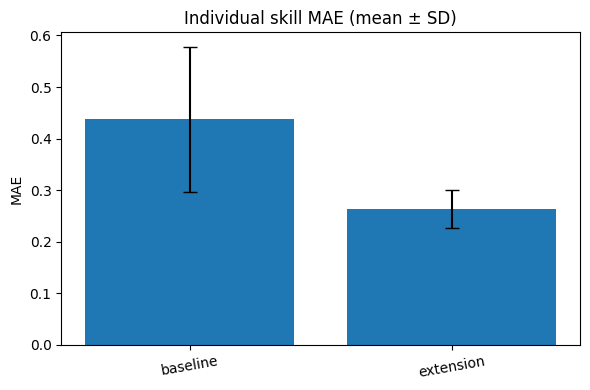

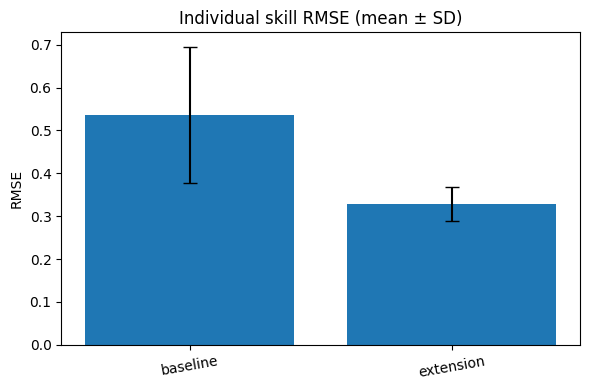

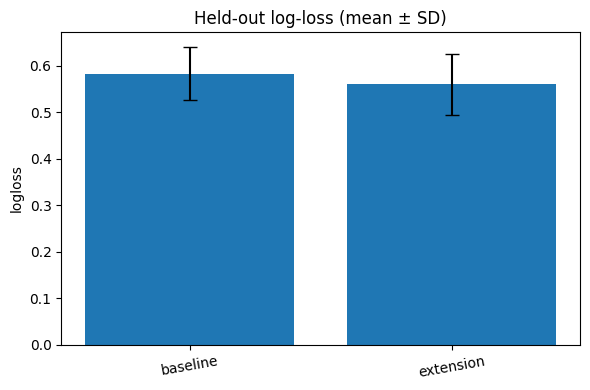

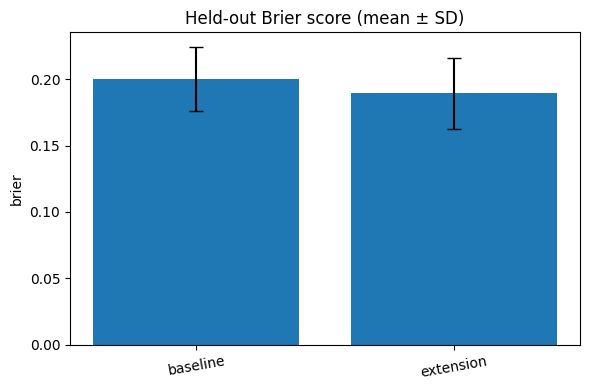

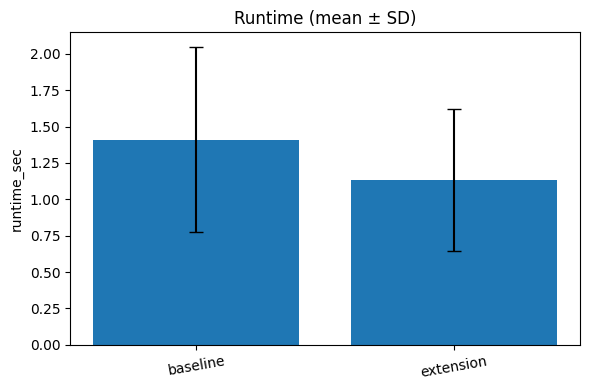

In [29]:
for metric,title in [("MAE","Individual skill MAE"),("RMSE","Individual skill RMSE"),
                     ("logloss","Held-out log-loss"),("brier","Held-out Brier score"),
                     ("runtime_sec","Runtime")]:
    g=main.groupby("model")[metric]
    plt.figure(figsize=(6,4))
    plt.bar(g.mean().index,g.mean().values,yerr=g.std().values,capsize=5)
    plt.ylabel(metric);plt.title(title+" (mean ± SD)");plt.xticks(rotation=10);plt.tight_layout();plt.show()

## 7. Robustness A — sample size

In [30]:
sample_rows=[]
for mpt in [6,12,24]:
    for seed in range(42,52):
        _,_,res,cut=run_experiment(seed=seed,matches_per_time=mpt)
        for model in ["baseline","extension"]:
            r=res[model]
            sample_rows.append({"matches_per_time":mpt,"seed":seed,"model":model,
                                "MAE":r["mae"],"logloss":r["logloss"],"brier":r["brier"],
                                "runtime_sec":r["runtime"]})
sample=pd.DataFrame(sample_rows)
display(sample.groupby(["matches_per_time","model"])[["MAE","logloss","brier","runtime_sec"]].agg(["mean","std"]).round(4))

MAE         logloss           brier          \
                              mean     std    mean     std    mean     std   
matches_per_time model                                                       
6                baseline   0.5037  0.0943  0.6019  0.0639  0.2047  0.0270   
                 extension  0.2989  0.0378  0.5815  0.0649  0.1966  0.0267   
12               baseline   0.4372  0.1400  0.5835  0.0568  0.1999  0.0242   
                 extension  0.2632  0.0366  0.5601  0.0655  0.1893  0.0269   
24               baseline   0.4527  0.1354  0.5788  0.0521  0.1978  0.0227   
                 extension  0.2392  0.0378  0.5580  0.0546  0.1891  0.0234   

                           runtime_sec          
                                  mean     std  
matches_per_time model                          
6                baseline       1.1844  0.5086  
                 extension      0.9656  0.3250  
12               baseline       0.9224  0.3564  
                 extension      0.7272  0.2691  
24               baseline       0.8447  0.2490  
                 extension      0.8574  0.2542

## 8. Robustness B — missing individual observations

In [31]:
missing_rows=[]
for miss in [0.0,0.25,0.50,0.75]:
    for seed in range(42,52):
        _,_,res,cut=run_experiment(seed=seed,missing_rate=miss)
        for model in ["baseline","extension"]:
            r=res[model]
            missing_rows.append({"missing_rate":miss,"seed":seed,"model":model,
                                 "MAE":r["mae"],"logloss":r["logloss"],"brier":r["brier"]})
missing=pd.DataFrame(missing_rows)
display(missing.groupby(["missing_rate","model"])[["MAE","logloss","brier"]].agg(["mean","std"]).round(4))

MAE         logloss           brier        
                          mean     std    mean     std    mean     std
missing_rate model                                                    
0.00         baseline   0.4372  0.1400  0.5835  0.0568  0.1999  0.0242
             extension  0.2632  0.0366  0.5601  0.0655  0.1893  0.0269
0.25         baseline   0.4372  0.1400  0.5835  0.0568  0.1999  0.0242
             extension  0.2656  0.0329  0.5604  0.0633  0.1895  0.0260
0.50         baseline   0.4372  0.1400  0.5835  0.0568  0.1999  0.0242
             extension  0.2740  0.0268  0.5609  0.0644  0.1896  0.0263
0.75         baseline   0.4372  0.1400  0.5835  0.0568  0.1999  0.0242
             extension  0.2937  0.0280  0.5612  0.0627  0.1895  0.0259

## 9. Robustness C — noise in individual observations

In [32]:
noise_rows=[]
for noise in [0.25,0.65,1.0,1.5]:
    for seed in range(42,52):
        _,_,res,cut=run_experiment(seed=seed,obs_noise=noise,obs_sd_model=noise)
        for model in ["baseline","extension"]:
            r=res[model]
            noise_rows.append({"observation_noise_sd":noise,"seed":seed,"model":model,
                               "MAE":r["mae"],"logloss":r["logloss"],"brier":r["brier"]})
noise=pd.DataFrame(noise_rows)
display(noise.groupby(["observation_noise_sd","model"])[["MAE","logloss","brier"]].agg(["mean","std"]).round(4))

MAE         logloss           brier        
                                  mean     std    mean     std    mean     std
observation_noise_sd model                                                    
0.25                 baseline   0.4372  0.1400  0.5835  0.0568  0.1999  0.0242
                     extension  0.2358  0.0408  0.5581  0.0662  0.1884  0.0275
0.65                 baseline   0.4372  0.1400  0.5835  0.0568  0.1999  0.0242
                     extension  0.2632  0.0366  0.5601  0.0655  0.1893  0.0269
1.00                 baseline   0.4372  0.1400  0.5835  0.0568  0.1999  0.0242
                     extension  0.2822  0.0351  0.5619  0.0646  0.1901  0.0264
1.50                 baseline   0.4372  0.1400  0.5835  0.0568  0.1999  0.0242
                     extension  0.3028  0.0403  0.5642  0.0633  0.1912  0.0259

## 10. Convergence, uncertainty and computational behaviour

In [33]:
conv=main.groupby("model").agg(
    mean_runtime=("runtime_sec","mean"),
    sd_runtime=("runtime_sec","std"),
    mean_iterations=("iterations","mean"),
    optimizer_success_rate=("optimizer_success","mean"),
    mean_posterior_sd=("mean_posterior_sd","mean"))
display(conv.round(4))

,mean_runtime,sd_runtime,mean_iterations,optimizer_success_rate,mean_posterior_sd
model,,,,,
baseline,1.4107,0.6349,164.5,1.0,0.6182
extension,1.1306,0.4892,67.4,1.0,0.3182


## 11. Calibration reliability diagram

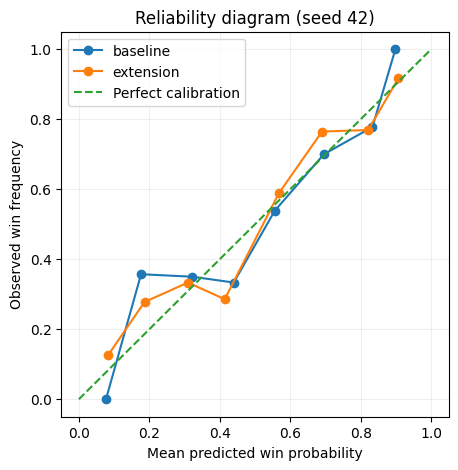

In [34]:
# Use a representative seed's held-out probabilities.
truth,data,res,cut=run_experiment(seed=42)
def reliability_bins(prob,labels,n_bins=8):
    frame=pd.DataFrame({"p":prob,"y":labels})
    frame["bin"]=pd.cut(frame.p,np.linspace(0,1,n_bins+1),include_lowest=True)
    return frame.groupby("bin",observed=False).agg(mean_probability=("p","mean"),observed_frequency=("y","mean"),count=("y","size")).dropna()
plt.figure(figsize=(5,5))
for model in ["baseline","extension"]:
    tab=reliability_bins(res[model]["p"],res[model]["y"])
    plt.plot(tab.mean_probability,tab.observed_frequency,marker="o",label=model)
plt.plot([0,1],[0,1],ls="--",label="Perfect calibration")
plt.xlabel("Mean predicted win probability");plt.ylabel("Observed win frequency")
plt.title("Reliability diagram (seed 42)");plt.legend();plt.grid(alpha=.2);plt.show()

## 12. Error analysis and ablation

In [35]:
# Compare individual skill errors by player for one representative seed.
truth,data,res,cut=run_experiment(seed=42)
player_rows=[]
for p in range(N_PLAYERS):
    for model in ["baseline","extension"]:
        err=res[model]["mu"][cut:,p]-truth[cut:,p]
        player_rows.append({"player":p,"model":model,"MAE":np.mean(np.abs(err))})
player_err=pd.DataFrame(player_rows)
display(player_err.pivot(index="player",columns="model",values="MAE").round(4))

model,baseline,extension
player,,
0,0.2174,0.4651
1,0.1381,0.1766
2,0.9457,0.1742
3,0.2884,0.2000
4,0.1860,0.1901
5,0.7783,0.4711
6,0.2836,0.1636
7,0.5621,0.1187
8,0.1451,0.1195


## 13. Export all report-ready results

In [36]:
os.makedirs("M3_Results",exist_ok=True)
main.to_csv("M3_Results/main_10_seed_results.csv",index=False)
summary.to_csv("M3_Results/main_summary_mean_sd.csv")
sample.to_csv("M3_Results/sample_size_robustness.csv",index=False)
missing.to_csv("M3_Results/missing_observation_robustness.csv",index=False)
noise.to_csv("M3_Results/observation_noise_robustness.csv",index=False)
player_err.to_csv("M3_Results/player_error_analysis_seed42.csv",index=False)
with open("M3_Results/paired_mae_test.json","w") as f:
    json.dump({"mean_baseline_minus_extension_mae":float(d.mean()),
               "bootstrap_95_ci":[float(ci[0]),float(ci[1])],
               "paired_t":float(tt.statistic),"p_value":float(tt.pvalue)},f,indent=2)
print("All result tables saved in M3_Results/")

All result tables saved in M3_Results/


In [37]:
import shutil
from google.colab import files

shutil.make_archive("M3_Results", "zip", "M3_Results")
files.download("M3_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import pandas as pd

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

_ (360, 10)
data (360, 10)
main (20, 10)
summary (2, 14)
wide (10, 2)
sample (60, 7)
missing (80, 6)
noise (80, 6)
conv (2, 5)
tab (8, 3)
player_err (24, 3)


In [39]:
print(data.columns.tolist())
print(data.head())

['time', 'a1', 'a2', 'b1', 'b2', 'a_wins', 'perf_a1', 'perf_a2', 'perf_b1', 'perf_b2']
   time  a1  a2  b1  b2  a_wins   perf_a1   perf_a2   perf_b1   perf_b2
0     0  11   1  10   2       0  1.740738 -1.574447  1.428248  1.614276
1     0  10   8   5   3       1 -0.422892 -0.314306 -0.450972  0.126994
2     0   2   4   3   0       1 -0.751116 -2.257690  1.396835 -0.125827
3     0   6   7   0   8       1  0.011093  0.217101  0.643476 -0.093204
4     0   6  10   7   9       1  0.614972  1.007962  0.546753 -1.353190


In [40]:
data.to_csv("synthetic_doubles_data.csv", index=False)

from google.colab import files
files.download("synthetic_doubles_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
import os
import shutil
from pathlib import Path
from google.colab import files

# Plot filenames expected
plot_names = [
    "MAE_comparison.png",
    "RMSE_comparison.png",
    "Log_loss_comparison.png",
    "Brier_score_comparison.png",
    "sample_size_robustness.png",
    "missing_observation_robustness.png",
    "observation_noise_robustness.png",
    "reliability_diagram_seed42.png"
]

# Create Plots folder
os.makedirs("Plots", exist_ok=True)

found = []
missing = []

for name in plot_names:
    matches = list(Path("/content").rglob(name))

    if matches:
        shutil.copy2(matches[0], f"Plots/{name}")
        found.append(name)
    else:
        missing.append(name)

# Show results
print("Plots found:", found)
print("Plots not found:", missing)

# ZIP the plots
if found:
    shutil.make_archive("M3_Plots", "zip", "Plots")
    files.download("M3_Plots.zip")
else:
    print("No saved plot images were found.")

Plots found: []
Plots not found: ['MAE_comparison.png', 'RMSE_comparison.png', 'Log_loss_comparison.png', 'Brier_score_comparison.png', 'sample_size_robustness.png', 'missing_observation_robustness.png', 'observation_noise_robustness.png', 'reliability_diagram_seed42.png']
No saved plot images were found.
